In [95]:
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns

from typing import cast

In [96]:
df = cast(pd.DataFrame, pd.read_csv("data/gym_churn_01.csv"))
df.shape

(4000, 14)

In [97]:
sns.set_theme(style="whitegrid")

In [98]:
display(df.head())
print("-" * 50)
df.info()

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
0,1,1,1,1,0,6,1,29,14.227470,5.0,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,12.0,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,1.0,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12.0,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,1.0,3,1.113884,1.120078,0


--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             4000 non-null   int64  
 1   Near_Location                      4000 non-null   int64  
 2   Partner                            4000 non-null   int64  
 3   Promo_friends                      4000 non-null   int64  
 4   Phone                              4000 non-null   int64  
 5   Contract_period                    4000 non-null   int64  
 6   Group_visits                       4000 non-null   int64  
 7   Age                                4000 non-null   int64  
 8   Avg_additional_charges_total       4000 non-null   float64
 9   Month_to_end_contract              4000 non-null   float64
 10  Lifetime                           4000 non-null   int64  
 11  Avg_class_freque

In [99]:
print("\nDistribution of churn variable:")
churn_dist = df["Churn"].value_counts(normalize=True) * 100
print(churn_dist)


Distribution of churn variable:
Churn
0    73.475
1    26.525
Name: proportion, dtype: float64


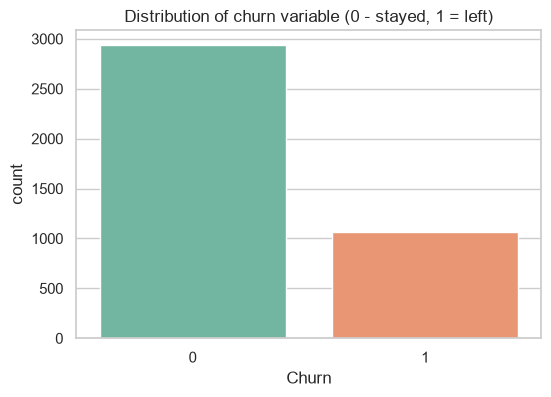

In [100]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn', hue="Churn", palette='Set2', legend=False)
plt.title('Distribution of churn variable (0 - stayed, 1 = left)')
plt.show()

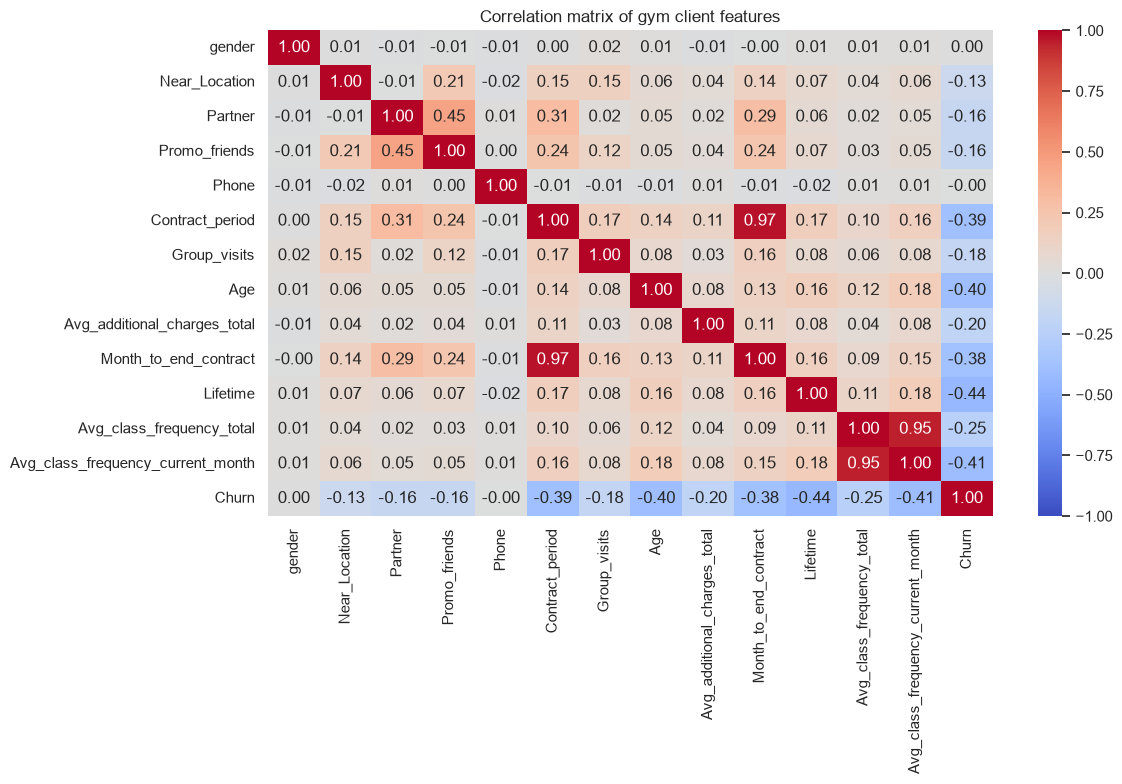

In [101]:
corr_matrix = df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, center=0)
plt.title("Correlation matrix of gym client features")
plt.tight_layout()
plt.show()

In [102]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report

In [103]:
df_cleaned = df.drop(columns=["Month_to_end_contract", "Avg_class_frequency_total"])
X = df_cleaned.drop('Churn', axis=1)
y = df_cleaned.pop("Churn")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y
)

log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", random_state=0)
)
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)
print("Classification report:")
print(classification_report(y_test, y_pred))

Classification report:
              precision    recall  f1-score   support

           0       0.98      0.88      0.93       588
           1       0.74      0.94      0.83       212

    accuracy                           0.90       800
   macro avg       0.86      0.91      0.88       800
weighted avg       0.91      0.90      0.90       800



In [104]:
df["frequency_delta"] = df["Avg_class_frequency_current_month"] - df["Avg_class_frequency_total"]
df_cleaned = df.drop(columns=["Month_to_end_contract", "Avg_class_frequency_total"])

X = df_cleaned.drop('Churn', axis=1)
y = df_cleaned.pop("Churn")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y
)

log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", random_state=0)
)
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)
print("Classification report:")
print(classification_report(y_test, y_pred))

Classification report:
              precision    recall  f1-score   support

           0       0.98      0.90      0.94       588
           1       0.78      0.94      0.85       212

    accuracy                           0.92       800
   macro avg       0.88      0.92      0.90       800
weighted avg       0.93      0.92      0.92       800



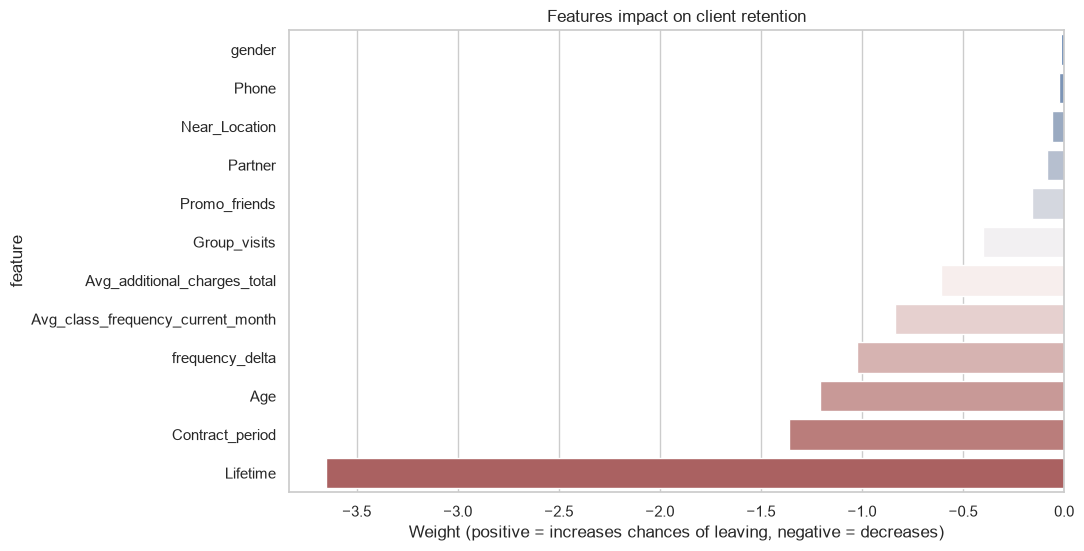

In [105]:
coefs = log_reg.named_steps["logisticregression"].coef_[0]

feature_importance = pd.DataFrame({
    "feature": X.columns,
    "coefficient": coefs,
}).sort_values(by="coefficient", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x='coefficient', y="feature", hue='feature', palette='vlag', legend=False)
plt.title('Features impact on client retention')
plt.xlabel('Weight (positive = increases chances of leaving, negative = decreases)')
plt.show()

In [107]:
df_cleaned.assign(Churn=y).to_csv('data/gym_churn_cleaned.csv', index=False)

In [108]:
import joblib
import os

model_dir = "../backend/app/ml/models"
os.makedirs(model_dir, exist_ok=True)

model_path = f"{model_dir}/gym_churn_baseline.joblib"
joblib.dump(log_reg, model_path)

print(f"Production model saved in: {model_path}")

Production model saved in: ../backend/app/ml/models/gym_churn_baseline.joblib
